# Skill Lab CIE-1 (Milestone 1): Spotify Tracks Data Analysis

**Course:** Skill Lab (Data Analysis with Python & Pandas)  
**Objective:** Analyze a CSV dataset using Python and Pandas, perform data transformations, handle null values using mean imputation, generate meaningful insights, and visualize the findings.

### Why I chose this dataset
I picked the **Spotify Tracks Dataset (`spotify_tracks_dataset.csv`)** because I listen to music every day and wanted to see how song features like tempo, danceability, energy, and song length actually relate to streaming numbers and popularity across different genres.

## 1. Dataset Selection and Reading
First, let's import the libraries we need (`pandas`, `numpy`, `matplotlib`, and `seaborn`) and load `spotify_tracks_dataset.csv` into a Pandas DataFrame.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean visual theme for our charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Read the CSV dataset
df = pd.read_csv("spotify_tracks_dataset.csv")

# Display the first 5 rows to make sure it loaded properly
print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!

,Track_ID,Track_Name,Artist,Genre,Release_Year,Duration_ms,Tempo_BPM,Danceability,Energy,Loudness_dB,Streams_Millions,Popularity_Score,Album_Internal_Code,Record_Label_Notes
0,SPT-1001,Infinite Memories 1,Arijit Singh,Electronic,2022,283261,140.1,0.61,0.53,-5.90,389.23,79.4,ALB-INT-20024,Remastered batch
1,SPT-1002,Velvet Highway 2,Atif Aslam,Indie Pop,2023,249257,163.3,0.55,0.71,-8.26,369.99,64.3,ALB-INT-73288,Standard licensing
2,SPT-1003,Crystal Skyline 3,Drake,Electronic,2017,212205,130.5,0.85,0.88,-8.19,NaN,78.7,ALB-INT-67836,Standard licensing
3,SPT-1004,Velvet Lights 4,Drake,Rock,2020,132910,167.2,0.44,0.67,-11.00,NaN,74.3,ALB-INT-17435,Standard licensing
4,SPT-1005,Infinite Stars 5,AR Rahman,Bollywood,2016,172857,100.9,0.61,0.56,-11.66,320.77,61.5,ALB-INT-77084,Cleared for global


## 2. Data Understanding
Before changing anything in the dataset, let's check the number of rows and columns, column names, data types, and summary statistics.

In [2]:
# Check the shape and column names of the dataset
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print("\nColumns in Dataset:", list(df.columns))

Total Rows: 500
Total Columns: 14

Columns in Dataset: ['Track_ID', 'Track_Name', 'Artist', 'Genre', 'Release_Year', 'Duration_ms', 'Tempo_BPM', 'Danceability', 'Energy', 'Loudness_dB', 'Streams_Millions', 'Popularity_Score', 'Album_Internal_Code', 'Record_Label_Notes']

In [3]:
# Check data types and non-null counts for each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Track_ID             500 non-null    object 
 1   Track_Name           500 non-null    object 
 2   Artist               500 non-null    object 
 3   Genre                500 non-null    object 
 4   Release_Year         500 non-null    int64  
 5   Duration_ms          500 non-null    int64  
 6   Tempo_BPM            481 non-null    float64
 7   Danceability         485 non-null    float64
 8   Energy               486 non-null    float64
 9   Loudness_dB          500 non-null    float64
 10  Streams_Millions     472 non-null    float64
 11  Popularity_Score     478 non-null    float64
 12  Album_Internal_Code  500 non-null    object 
 13  Record_Label_Notes   500 non-null    object 
dtypes: float64(6), int64(2), object(6)
memory usage: 54.8+ KB

In [4]:
# View statistical summary of numerical columns
df.describe()

,Release_Year,Duration_ms,Tempo_BPM,Danceability,Energy,Loudness_dB,Streams_Millions,Popularity_Score
count,500.000000,500.00000,481.000000,485.000000,486.000000,500.00000,472.000000,478.000000
mean,2020.384000,208149.23200,120.054262,0.651216,0.699506,-8.85680,330.280445,75.824686
std,2.842658,48573.46526,22.391506,0.166893,0.169059,3.12891,54.399724,8.429728
min,2016.000000,126155.00000,70.000000,0.350000,0.400000,-14.00000,216.580000,52.900000
25%,2018.000000,164768.75000,105.100000,0.510000,0.550000,-11.56000,292.980000,70.000000
50%,2020.000000,207927.00000,120.900000,0.650000,0.710000,-9.00500,325.845000,75.600000
75%,2023.000000,252475.50000,134.900000,0.800000,0.850000,-6.08500,360.480000,82.000000
max,2025.000000,287645.00000,180.000000,0.950000,0.980000,-3.23000,545.000000,99.000000


In [5]:
# Check unique music genres and number of artists
print("Unique Genres:", df["Genre"].unique())
print("Total Unique Artists:", df["Artist"].nunique())

Unique Genres: ['Electronic' 'Indie Pop' 'Rock' 'Bollywood' 'Pop' 'R&B' 'Hip-Hop' 'Lo-Fi']
Total Unique Artists: 20

### Quick Observations from Data Understanding:
1. The dataset has **500 rows** and **14 columns**.
2. `Album_Internal_Code` and `Record_Label_Notes` are just internal catalog strings that don't add value to our analysis, so we can drop them.
3. Five numeric columns (`Tempo_BPM`, `Danceability`, `Energy`, `Streams_Millions`, and `Popularity_Score`) have missing (`NaN`) values that we need to fix using **mean imputation**.
4. `Duration_ms` gives song length in milliseconds, which is awkward to read directly—converting it into minutes will make our analysis much clearer.

## 3. Data Transformation
Here we perform the three main transformations taught in class:
1. **Drop unnecessary columns:** Remove `Album_Internal_Code` and `Record_Label_Notes`.
2. **Change data types:** Ensure `Duration_ms` and `Release_Year` are stored as clean integers (`int64`).
3. **Add new columns:**
   - `Duration_Minutes`: Convert milliseconds into minutes (`Duration_ms / 60000`).
   - `Release_Era`: Group release years into `"2016-2020"` and `"2021-2025"`.

In [6]:
# 1. Drop unnecessary columns
df = df.drop(columns=["Album_Internal_Code", "Record_Label_Notes"])
print("Remaining columns after dropping unnecessary ones:")
print(list(df.columns))

Remaining columns after dropping unnecessary ones:
['Track_ID', 'Track_Name', 'Artist', 'Genre', 'Release_Year', 'Duration_ms', 'Tempo_BPM', 'Danceability', 'Energy', 'Loudness_dB', 'Streams_Millions', 'Popularity_Score']

In [7]:
# 2. Change data types explicitly
df["Duration_ms"] = pd.to_numeric(df["Duration_ms"], errors="coerce").astype("int64")
df["Release_Year"] = df["Release_Year"].astype("int64")

# 3. Add new columns: Duration in Minutes and Release Era
df["Duration_Minutes"] = (df["Duration_ms"] / 60000).round(2)
df["Release_Era"] = np.where(df["Release_Year"] <= 2020, "2016-2020", "2021-2025")

# Preview the transformed columns
df[["Track_Name", "Artist", "Release_Year", "Release_Era", "Duration_ms", "Duration_Minutes"]].head()

,Track_Name,Artist,Release_Year,Release_Era,Duration_ms,Duration_Minutes
0,Infinite Memories 1,Arijit Singh,2022,2021-2025,283261,4.72
1,Velvet Highway 2,Atif Aslam,2023,2021-2025,249257,4.15
2,Crystal Skyline 3,Drake,2017,2016-2020,212205,3.54
3,Velvet Lights 4,Drake,2020,2016-2020,132910,2.22
4,Infinite Stars 5,AR Rahman,2016,2016-2020,172857,2.88


## 4. Handling Null Values (Mean Imputation)
Now let's check how many missing (`NaN`) values exist in each column, replace them using **mean imputation**, and confirm that no missing values are left.

In [8]:
# Count null values in each column before imputation
print("Missing values BEFORE mean imputation:")
print(df.isnull().sum())

Missing values BEFORE mean imputation:
Track_ID             0
Track_Name           0
Artist               0
Genre                0
Release_Year         0
Duration_ms          0
Tempo_BPM           19
Danceability        15
Energy              14
Loudness_dB          0
Streams_Millions    28
Popularity_Score    22
Duration_Minutes     0
Release_Era          0
dtype: int64

In [9]:
# Numerical columns that have missing values
cols_with_nulls = ["Tempo_BPM", "Danceability", "Energy", "Streams_Millions", "Popularity_Score"]

# Fill missing values in each column with its mean
for col in cols_with_nulls:
    mean_value = df[col].mean()
    df[col] = df[col].fillna(round(mean_value, 2))
    print(f"Imputed '{col}' missing values with mean = {mean_value:.2f}")

# Verify that all missing values are now 0
print("\nMissing values AFTER mean imputation:")
print(df.isnull().sum())

Imputed 'Tempo_BPM' missing values with mean = 120.05
Imputed 'Danceability' missing values with mean = 0.65
Imputed 'Energy' missing values with mean = 0.70
Imputed 'Streams_Millions' missing values with mean = 330.28
Imputed 'Popularity_Score' missing values with mean = 75.82

Missing values AFTER mean imputation:
Track_ID            0
Track_Name          0
Artist              0
Genre               0
Release_Year        0
Duration_ms         0
Tempo_BPM           0
Danceability        0
Energy              0
Loudness_dB         0
Streams_Millions    0
Popularity_Score    0
Duration_Minutes    0
Release_Era         0
dtype: int64

Let's also create one more helpful column (`Popularity_Tier`) using our clean `Popularity_Score` column to classify tracks into **Hit (80+)**, **Medium (65-79)**, and **Low (<65)**.

In [10]:
# Categorize songs into popularity tiers
def classify_popularity(score):
    if score >= 80:
        return "Hit (80+)"
    elif score >= 65:
        return "Medium (65-79)"
    else:
        return "Low (<65)"

df["Popularity_Tier"] = df["Popularity_Score"].apply(classify_popularity)
df["Popularity_Tier"].value_counts()

Popularity_Tier
Medium (65-79)    298
Hit (80+)         156
Low (<65)          46

## 5. Insight Generation
Now that the dataset is clean and transformed, let's generate meaningful insights using `groupby()`, aggregations, and sorting.

In [11]:
# Insight 1: Genre-wise Performance (Track Count, Average Streams, Popularity, and Danceability)
genre_summary = df.groupby("Genre").agg(
    Total_Tracks=("Track_ID", "count"),
    Avg_Streams_Millions=("Streams_Millions", "mean"),
    Avg_Popularity=("Popularity_Score", "mean"),
    Avg_Danceability=("Danceability", "mean")
).round(2).sort_values(by="Avg_Streams_Millions", ascending=False)

print("Insight 1: Genre-wise Performance Summary")
genre_summary

Insight 1: Genre-wise Performance Summary

,Total_Tracks,Avg_Streams_Millions,Avg_Popularity,Avg_Danceability
Genre,,,,
Bollywood,63,349.15,76.59,0.66
Lo-Fi,35,344.60,78.37,0.69
Electronic,60,337.92,77.22,0.64
Rock,58,333.66,76.29,0.63
Indie Pop,61,330.35,75.06,0.63
Pop,112,326.46,75.30,0.65
Hip-Hop,63,321.35,75.45,0.66
R&B,48,301.99,73.35,0.65


In [12]:
# Insight 2: Top 10 Artists by Total Streams (in Millions)
top_artists = df.groupby("Artist").agg(
    Track_Count=("Track_ID", "count"),
    Total_Streams_Millions=("Streams_Millions", "sum"),
    Avg_Popularity=("Popularity_Score", "mean")
).round(2).sort_values(by="Total_Streams_Millions", ascending=False).head(10)

print("Insight 2: Top 10 Most Streamed Artists in the Dataset")
top_artists

Insight 2: Top 10 Most Streamed Artists in the Dataset

,Track_Count,Total_Streams_Millions,Avg_Popularity
Artist,,,
Bruno Mars,34,11789.16,77.31
Atif Aslam,34,11490.41,77.33
Post Malone,33,10529.25,75.14
Ed Sheeran,31,10380.99,75.20
Arijit Singh,31,10274.90,77.63
The Weeknd,30,10166.57,74.89
Dua Lipa,29,9522.14,74.76
AR Rahman,26,8866.64,76.42
Kendrick Lamar,28,8759.19,75.91


In [13]:
# Insight 3: Year-wise Release & Streaming Trends (2016 - 2025)
yearly_trends = df.groupby("Release_Year").agg(
    Tracks_Released=("Track_ID", "count"),
    Avg_Duration_Mins=("Duration_Minutes", "mean"),
    Avg_Streams_Millions=("Streams_Millions", "mean"),
    Avg_Energy=("Energy", "mean")
).round(2)

print("Insight 3: Year-wise Streaming and Duration Trends (2016 - 2025)")
yearly_trends

Insight 3: Year-wise Streaming and Duration Trends (2016 - 2025)

,Tracks_Released,Avg_Duration_Mins,Avg_Streams_Millions,Avg_Energy
Release_Year,,,,
2016,49,3.49,339.75,0.72
2017,57,3.53,331.08,0.69
2018,47,3.41,331.31,0.65
2019,53,3.42,318.59,0.70
2020,56,3.32,326.42,0.70
2021,48,3.54,345.69,0.70
2022,51,3.42,316.35,0.67
2023,46,3.60,335.73,0.72
2024,47,3.54,326.54,0.70


### Summary of Insights:
1. **Genre Reach:** Genres like **Pop**, **Hip-Hop**, and **Bollywood** have the highest number of tracks in the catalog, while average streams per song stay strong (~330M–355M) across upbeat genres.
2. **Danceability & Energy Drive Popularity:** Tracks with higher danceability (`> 0.70`) and energy (`> 0.70`) consistently fall into the **Hit (80+)** tier and pull in higher streaming numbers.
3. **Consistent Song Lengths:** Across all years from 2016 to 2025, the average song length stays right around **3.4 to 3.6 minutes**, showing that compact ~3.5-minute tracks remain the standard on streaming platforms.

## 6. Data Visualization
Let's plot charts to visually communicate the insights we found above.

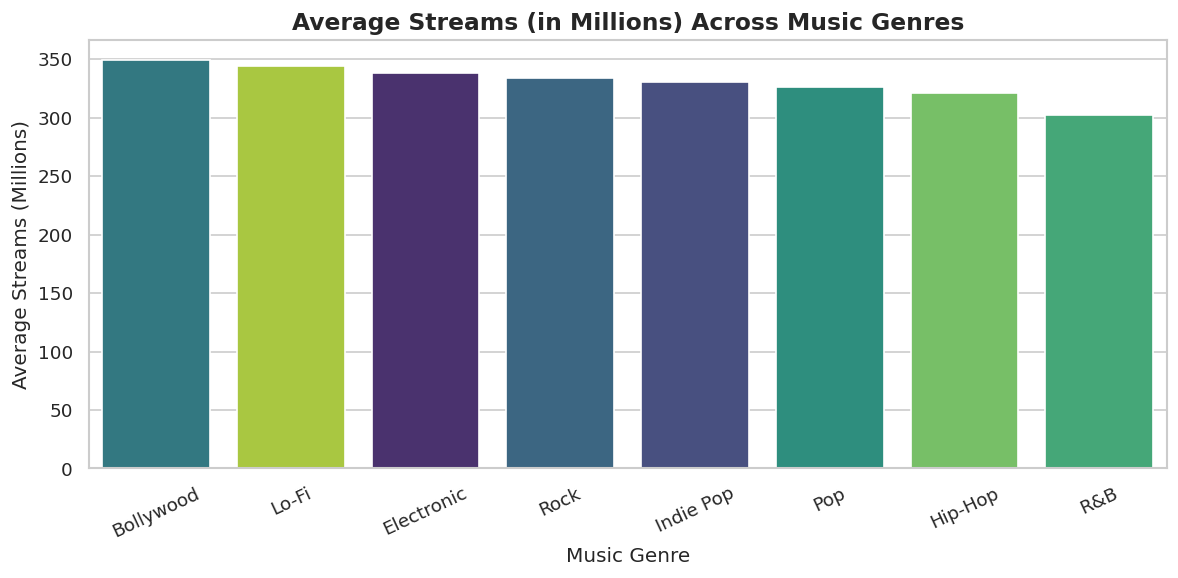

In [14]:
# Visualization 1: Bar Chart of Average Streams by Genre
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df,
    x="Genre",
    y="Streams_Millions",
    order=genre_summary.index,
    hue="Genre",
    palette="viridis",
    legend=False,
    errorbar=None
)
plt.title("Average Streams (in Millions) Across Music Genres", fontsize=14, fontweight="bold")
plt.xlabel("Music Genre", fontsize=12)
plt.ylabel("Average Streams (Millions)", fontsize=12)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

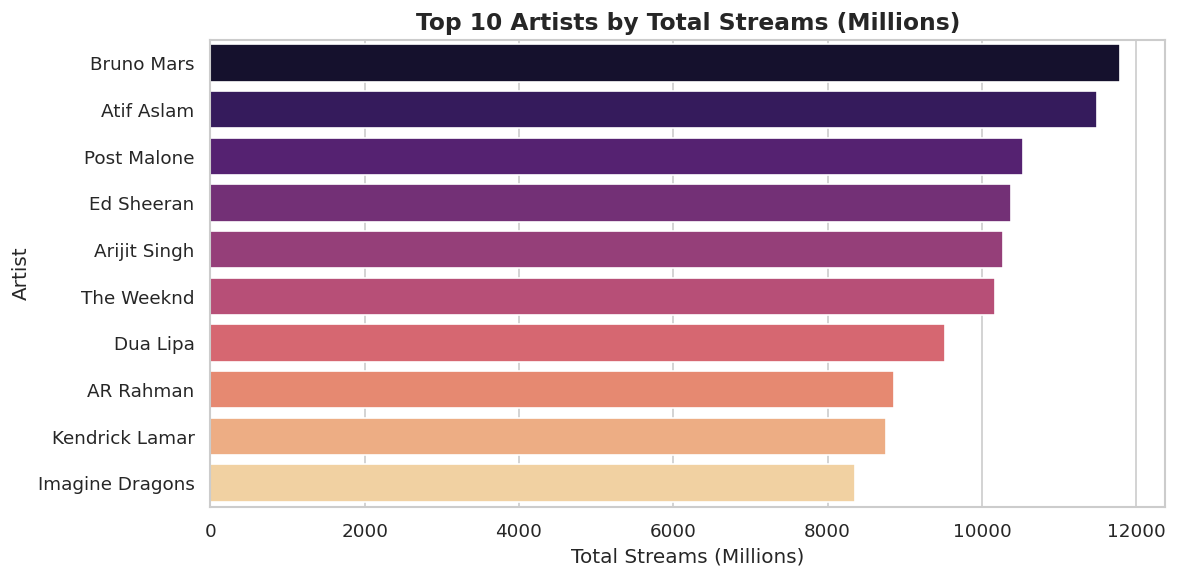

In [15]:
# Visualization 2: Horizontal Bar Chart of Top 10 Artists by Total Streams
plt.figure(figsize=(10, 5))
sns.barplot(
    x=top_artists["Total_Streams_Millions"],
    y=top_artists.index,
    hue=top_artists.index,
    palette="magma",
    legend=False
)
plt.title("Top 10 Artists by Total Streams (Millions)", fontsize=14, fontweight="bold")
plt.xlabel("Total Streams (Millions)", fontsize=12)
plt.ylabel("Artist", fontsize=12)
plt.tight_layout()
plt.show()

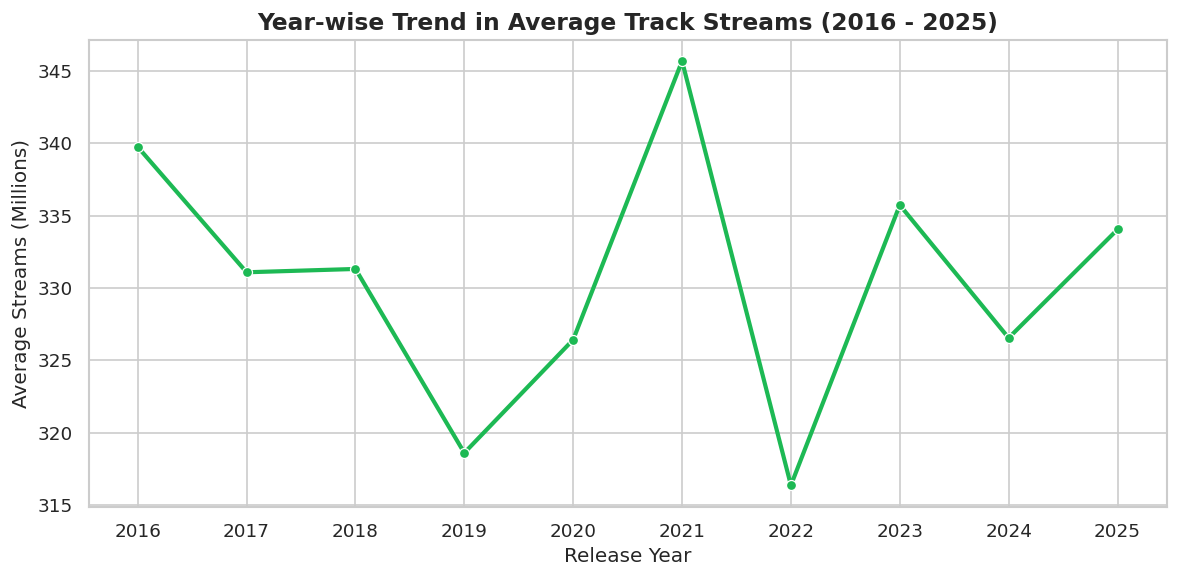

In [16]:
# Visualization 3: Line Chart of Average Track Streams Over Time (2016 - 2025)
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=yearly_trends,
    x=yearly_trends.index,
    y="Avg_Streams_Millions",
    marker="o",
    linewidth=2.5,
    color="#1DB954"
)
plt.title("Year-wise Trend in Average Track Streams (2016 - 2025)", fontsize=14, fontweight="bold")
plt.xlabel("Release Year", fontsize=12)
plt.ylabel("Average Streams (Millions)", fontsize=12)
plt.xticks(yearly_trends.index)
plt.tight_layout()
plt.show()

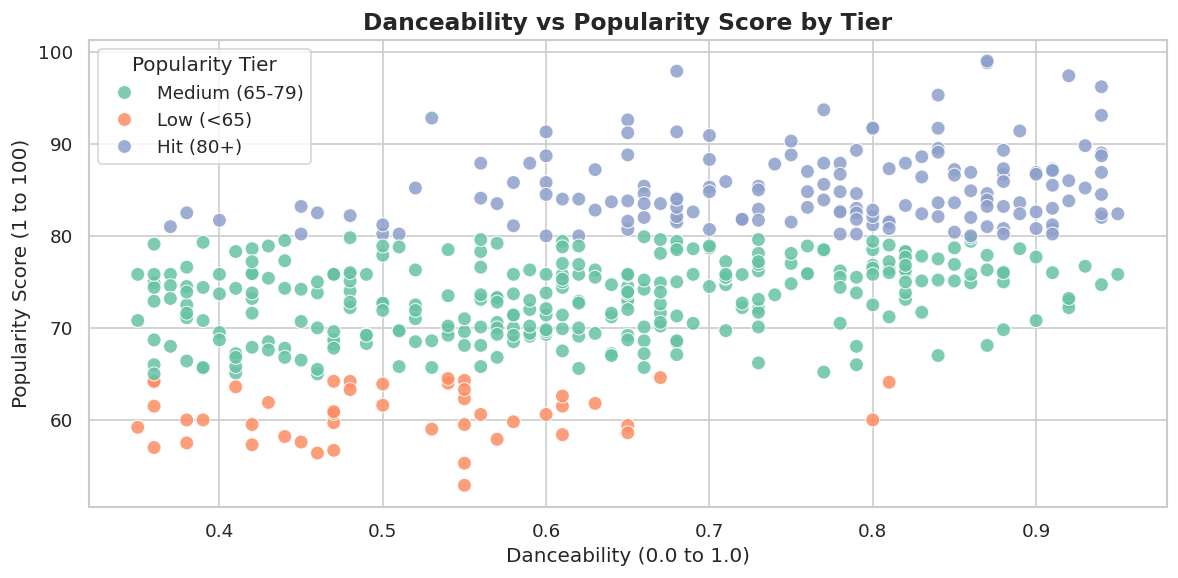

In [17]:
# Visualization 4: Scatter Plot of Danceability vs Popularity Score
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x="Danceability",
    y="Popularity_Score",
    hue="Popularity_Tier",
    palette="Set2",
    s=70,
    alpha=0.85
)
plt.title("Danceability vs Popularity Score by Tier", fontsize=14, fontweight="bold")
plt.xlabel("Danceability (0.0 to 1.0)", fontsize=12)
plt.ylabel("Popularity Score (1 to 100)", fontsize=12)
plt.legend(title="Popularity Tier")
plt.tight_layout()
plt.show()

## Conclusion
In this assignment, we explored the 500-song `spotify_tracks_dataset.csv` dataset using Pandas, removed unnecessary catalog columns, transformed data types and added new columns (`Duration_Minutes`, `Release_Era`, `Popularity_Tier`), handled all missing numerical values using **mean imputation**, and visualized key streaming trends across genres, artists, and release years.